# Third Model - HistGradientBoostingRegressor

**Why this model?**

The exploratory analysis revealed several patterns that may be difficult to represent with simple additive models:

- The relationship between temperature and rental demand is non-linear.
- Hourly demand patterns differ substantially between working days and non-working days.
- Weather conditions may affect demand differently depending on the hour.
- Demand contains strong temporal patterns and interactions between calendar features.

Gradient Boosting builds an ensemble of decision trees sequentially, with each new tree correcting errors made by the previous ones. This allows the model to learn non-linear relationships and feature interactions directly from the data.

We use `HistGradientBoostingRegressor` because it is computationally efficient for datasets of this size and supports missing values and categorical features natively.

The main objectives of this experiment are:

1. Evaluate the performance of Gradient Boosting under random, blocked, and chronological validation.
2. Compare squared error and Poisson loss.
3. Compare both Gradient Boosting variants with the baseline models.
4. Investigate how prediction errors change over time and whether the model captures the increase in demand between 2011 and 2012.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import ast

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.inspection import permutation_importance

from src.data import load_data
from src.validation import RESULTS_DIR, SCHEMES, SEED, compute_metrics, evaluate, get_cv

FIGURES_DIR = Path("figures/gradient_boosting")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

CATEGORICAL_FEATURES = ["hr", "mnth", "weekday", "weathersit"]

In [2]:
X, y = load_data(drop__yr=True)
CATEGORICAL_MASK = np.array([col in CATEGORICAL_FEATURES for col in X.columns])

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Categorical features:", X.columns[CATEGORICAL_MASK].tolist())
display(X.head())

X shape: (17379, 9)
y shape: (17379,)
Categorical features: ['mnth', 'hr', 'weekday', 'weathersit']


,mnth,hr,holiday,weekday,workingday,weathersit,temp,hum,windspeed
datetime,,,,,,,,,
2011-01-01 00:00:00,1,0,0,6,0,1,0.24,0.81,0.0
2011-01-01 01:00:00,1,1,0,6,0,1,0.22,0.80,0.0
2011-01-01 02:00:00,1,2,0,6,0,1,0.22,0.80,0.0
2011-01-01 03:00:00,1,3,0,6,0,1,0.24,0.75,0.0
2011-01-01 04:00:00,1,4,0,6,0,1,0.24,0.75,0.0


In [3]:
assert X.index.equals(y.index)
assert X.index.is_monotonic_increasing
assert X.index.is_unique
assert "yr" not in X.columns
assert X["hum"].isna().sum() == 22
assert CATEGORICAL_MASK.sum() == 4
assert all(X[col].nunique() <= 255 for col in CATEGORICAL_FEATURES)

print("Chronological order:", X.index.is_monotonic_increasing)
print("Unique timestamps:", X.index.is_unique)
print("Year excluded:", "yr" not in X.columns)
print("Missing humidity values:", X["hum"].isna().sum())
print("Categorical features:", X.columns[CATEGORICAL_MASK].tolist())
print("Validation schemes:", SCHEMES)

Chronological order: True
Unique timestamps: True
Year excluded: True
Missing humidity values: 22
Categorical features: ['mnth', 'hr', 'weekday', 'weathersit']
Validation schemes: ('random', 'blocked', 'chrono')


In [4]:
print("Features:")
print(X.columns.tolist())

print("\nMissing values:")
display(X.isna().sum())

Features:
['mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'hum', 'windspeed']

Missing values:


mnth           0
hr             0
holiday        0
weekday        0
workingday     0
weathersit     0
temp           0
hum           22
windspeed      0
dtype: int64

## Preprocessing

HistGradientBoostingRegressor does not require feature scaling, one-hot encoding, or manually constructed interaction features.

We use four categorical features:

- `hr`
- `mnth`
- `weekday`
- `weathersit`

These variables are encoded as integer category codes in the original dataset. We explicitly mark them as categorical using the `categorical_features` mask, so the model does not interpret their numerical codes as ordered continuous quantities.

The remaining features are:

- Binary indicators: `holiday`, `workingday`
- Continuous weather features: `temp`, `hum`, `windspeed`

Missing values in `hum` are retained as `NaN`. HistGradientBoostingRegressor handles missing values natively, so no imputation is required.

No scaling, one-hot encoding, polynomial expansion, or manually engineered interactions are applied. The model learns non-linear relationships and interactions through its tree structure.

## Gradient Boosting and Hyperparameters

Gradient Boosting builds an ensemble of decision trees sequentially. Each new tree attempts to reduce the remaining prediction error of the current ensemble.

The complexity and learning behaviour of the model are controlled by several hyperparameters:

- `learning_rate` controls the contribution of each new tree. Smaller values usually require more iterations.
- `max_iter` determines the number of boosting iterations.
- `max_leaf_nodes` limits the number of leaves in each tree and therefore controls its complexity.
- `min_samples_leaf` specifies the minimum number of training observations in a leaf. Larger values produce smoother models and reduce the ability to fit very local patterns.
- `l2_regularization` penalises large leaf values and can help prevent overfitting.

We disable automatic early stopping (`early_stopping=False`). By default, early stopping may use a random validation subset of the training data. This would introduce an additional random validation procedure into our chronological experiment.

Instead, the number of iterations is selected through the same inner cross-validation strategy used for the corresponding outer validation scheme.

In [5]:
PARAM_GRID = {
    "learning_rate": [0.05, 0.1],
    "max_iter": [200, 500],
    "max_leaf_nodes": [15, 31],
    "min_samples_leaf": [20, 100],
    "l2_regularization": [0.0, 10.0],
}

In [6]:
def make_hgb_search(scheme, loss="squared_error"):
    model = HistGradientBoostingRegressor(loss=loss, categorical_features=CATEGORICAL_MASK, early_stopping=False, random_state=SEED)
    return GridSearchCV(estimator=model, param_grid=PARAM_GRID, scoring="neg_root_mean_squared_error", cv=get_cv(scheme, n_splits=3), refit=True, n_jobs=-1, return_train_score=True)

In [7]:
print("Target minimum:", y.min())
print("Target maximum:", y.max())
print("All target values non-negative:", (y >= 0).all())

Target minimum: 1
Target maximum: 977
All target values non-negative: True


## Computational Cost

Before running the full experiment, we measure the time required for one hyperparameter search.
The grid contains 32 parameter combinations, evaluated with three inner cross-validation splits. The complete experiment repeats this search across the outer folds, validation schemes, and loss functions.
The benchmark is used only to estimate computational cost. Its best inner-CV score is not treated as an unbiased estimate of model performance because it is calculated on the full dataset during hyperparameter search.

In [8]:
benchmark_scheme = "random"

start = time.perf_counter()

benchmark_search = make_hgb_search(scheme=benchmark_scheme, loss="squared_error")
benchmark_search.fit(X, y)
benchmark_time = time.perf_counter() - start

print(f"Benchmark time: {benchmark_time:.2f} seconds")
print("Best parameters:", benchmark_search.best_params_)
print("Best inner CV RMSE:", -benchmark_search.best_score_)

Benchmark time: 75.49 seconds
Best parameters: {'l2_regularization': 0.0, 'learning_rate': 0.05, 'max_iter': 500, 'max_leaf_nodes': 31, 'min_samples_leaf': 20}
Best inner CV RMSE: 65.32767934990817


## Validation Strategy and Hyperparameter Tuning

We use the same nested cross-validation framework as in the Ridge experiment.

The outer validation estimates generalisation performance using three schemes:

- **Random K-Fold:** randomly distributes observations across training and test folds.
- **Blocked validation:** evaluates the model on contiguous time blocks while allowing training observations from both sides of the test block.
- **Chronological validation:** trains on earlier observations and evaluates on later observations.

For each outer training fold, `GridSearchCV` selects the hyperparameters using three inner splits generated by the corresponding validation scheme.

The outer test fold is not used during hyperparameter selection. After selecting the best parameter combination, the estimator is refitted on the full outer training fold and evaluated on the untouched test fold.

Automatic early stopping is disabled to avoid introducing a separate random validation subset into the chronological experiment.

## Model Training and Evaluation

We evaluate two HistGradientBoostingRegressor variants:

- **HGB:** uses the squared error loss.
- **HGB Poisson:** uses the Poisson loss with a logarithmic link function.

Both variants use the same feature set, hyperparameter grid, and nested cross-validation procedure.

We evaluate each model under all three validation schemes to determine how the model's flexibility affects the difference between random, blocked, and chronological validation.

In [9]:
hgb_results = {}
loss_variants = {"hgb": "squared_error", "hgb_poisson": "poisson"}

for name, loss in loss_variants.items():
    for scheme in SCHEMES:
        print(f"\nRunning {name} — {scheme}")
        search = make_hgb_search(scheme, loss)
        start = time.perf_counter()
        folds, preds = evaluate(model=search, X=X, y=y, scheme=scheme, name=name, n_splits=5, seed=SEED, save=True)
        hgb_results[(name, scheme)] = (folds, preds)
        print(f"Completed in {(time.perf_counter() - start) / 60:.2f} minutes")
        print(f"Mean RMSE: {folds['rmse'].mean():.3f}")
        print(f"Mean MAE: {folds['mae'].mean():.3f}")


Running hgb — random
Completed in 3.32 minutes
Mean RMSE: 64.706
Mean MAE: 43.188

Running hgb — blocked
Completed in 2.80 minutes
Mean RMSE: 114.686
Mean MAE: 83.373

Running hgb — chrono
Completed in 2.98 minutes
Mean RMSE: 120.689
Mean MAE: 87.237

Running hgb_poisson — random
Completed in 3.46 minutes
Mean RMSE: 62.980
Mean MAE: 41.208

Running hgb_poisson — blocked
Completed in 3.02 minutes
Mean RMSE: 114.967
Mean MAE: 82.753

Running hgb_poisson — chrono
Completed in 2.99 minutes
Mean RMSE: 121.375
Mean MAE: 87.164


## HGB Performance Summary

We first summarise the performance of both Gradient Boosting variants under the three validation schemes.

The table reports the mean and standard deviation of the evaluation metrics across the outer folds. This allows us to examine both average predictive performance and its variability across different test periods.

In [10]:
summary_rows = []
model_names = ["baseline_const", "baseline_hour_day", "hgb", "hgb_poisson"]

for model_name in model_names:
    for scheme in SCHEMES:
        folds = hgb_results[(model_name, scheme)][0] if model_name in ["hgb", "hgb_poisson"] else pd.read_csv(RESULTS_DIR / f"{model_name}_{scheme}_folds.csv")
        summary_rows.append({"model": model_name, "scheme": scheme, "rmse_mean": folds["rmse"].mean(), "rmse_std": folds["rmse"].std(), "mae_mean": folds["mae"].mean(), "mae_std": folds["mae"].std(), "r2_mean": folds["r2"].mean(), "rmsle_mean": folds["rmsle"].mean()})

summary = pd.DataFrame(summary_rows)
display(summary.sort_values(["scheme", "rmse_mean"]).round(3))

,model,scheme,rmse_mean,rmse_std,mae_mean,mae_std,r2_mean,rmsle_mean
7,hgb,blocked,114.686,13.162,83.373,10.649,0.438,0.662
10,hgb_poisson,blocked,114.967,12.755,82.753,10.787,0.441,0.586
4,baseline_hour_day,blocked,119.111,38.852,83.458,30.843,0.304,0.658
1,baseline_const,blocked,182.116,47.228,147.169,28.762,-0.280,1.575
8,hgb,chrono,120.689,12.736,87.237,11.157,0.611,0.614
11,hgb_poisson,chrono,121.375,11.912,87.164,10.460,0.602,0.522
5,baseline_hour_day,chrono,133.292,44.825,95.482,36.770,0.562,0.580
2,baseline_const,chrono,215.611,52.739,165.455,38.785,-0.159,1.443
9,hgb_poisson,random,62.980,1.222,41.208,1.021,0.879,0.384
6,hgb,random,64.706,1.280,43.188,0.821,0.873,0.493


The table reports the mean outer-fold metrics for the baseline and Gradient Boosting models.

These fold-averaged scores are useful for comparing models within the same validation scheme. However, the validation schemes test different observations, so their scores should not be directly compared with each other.

To isolate the effect of the validation strategy, we additionally compare all schemes on exactly the same test timestamps.

## Comparison with Baseline Models

We compare the Gradient Boosting models with the baseline models using the predictions saved during the previous experiments.

For each validation scheme, we first align predictions by timestamp. This ensures that the models are evaluated on exactly the same observations.

We report RMSE and MAE for the common test observations. The comparison is based on predictions from the outer cross-validation folds, not on the inner hyperparameter search scores.

In [11]:
def load_preds(name, scheme):
    preds = pd.read_csv(RESULTS_DIR / f"{name}_{scheme}_preds.csv", index_col=0, parse_dates=True)
    preds.index.name = "datetime"
    return preds.sort_index()

baseline_models = ["baseline_const", "baseline_hour_day"]
hgb_models = ["hgb", "hgb_poisson"]
comparison_rows = []
matched_predictions = {}

for scheme in SCHEMES:
    for baseline_name in baseline_models:
        baseline_preds = load_preds(baseline_name, scheme)
        for hgb_name in hgb_models:
            hgb_preds = load_preds(hgb_name, scheme)
            common_index = baseline_preds.index.intersection(hgb_preds.index).sort_values()
            baseline_common = baseline_preds.loc[common_index]
            hgb_common = hgb_preds.loc[common_index]
            assert baseline_common.index.equals(hgb_common.index)
            assert np.allclose(baseline_common["y_true"], hgb_common["y_true"])
            b_metrics = compute_metrics(baseline_common["y_true"], baseline_common["y_pred"])
            h_metrics = compute_metrics(hgb_common["y_true"], hgb_common["y_pred"])
            comparison_rows.append({"scheme": scheme, "baseline": baseline_name, "model": hgb_name, "n_common": len(common_index), "baseline_rmse": b_metrics["rmse"], "model_rmse": h_metrics["rmse"], "rmse_improvement": b_metrics["rmse"] - h_metrics["rmse"], "baseline_mae": b_metrics["mae"], "model_mae": h_metrics["mae"], "mae_improvement": b_metrics["mae"] - h_metrics["mae"]})
            matched_predictions[(scheme, baseline_name, hgb_name)] = (baseline_common, hgb_common)

baseline_comparison = pd.DataFrame(comparison_rows)
display(baseline_comparison.sort_values(["scheme", "baseline", "model"]).round(3))

,scheme,baseline,model,n_common,baseline_rmse,model_rmse,rmse_improvement,baseline_mae,model_mae,mae_improvement
4,blocked,baseline_const,hgb,17379,186.948,115.288,71.660,147.168,83.372,63.795
5,blocked,baseline_const,hgb_poisson,17379,186.948,115.531,71.417,147.168,82.753,64.415
6,blocked,baseline_hour_day,hgb,17379,124.075,115.288,8.787,83.457,83.372,0.085
7,blocked,baseline_hour_day,hgb_poisson,17379,124.075,115.531,8.544,83.457,82.753,0.704
8,chrono,baseline_const,hgb,8722,220.904,121.285,99.619,165.586,87.296,78.291
9,chrono,baseline_const,hgb_poisson,8722,220.904,121.906,98.998,165.586,87.225,78.362
10,chrono,baseline_hour_day,hgb,8722,139.359,121.285,18.074,95.637,87.296,8.341
11,chrono,baseline_hour_day,hgb_poisson,8722,139.359,121.906,17.453,95.637,87.225,8.412
0,random,baseline_const,hgb,17379,181.399,64.716,116.683,142.415,43.188,99.227
1,random,baseline_const,hgb_poisson,17379,181.399,62.989,118.410,142.415,41.208,101.207


A positive RMSE or MAE improvement means that the Gradient Boosting model performs better than the corresponding baseline on the same test observations. A negative value means that the baseline performs better.

In [12]:
baseline_comparison["rmse_improvement_pct"] = baseline_comparison["rmse_improvement"] / baseline_comparison["baseline_rmse"] * 100
baseline_comparison["mae_improvement_pct"] = baseline_comparison["mae_improvement"] / baseline_comparison["baseline_mae"] * 100

display(baseline_comparison[["scheme", "baseline", "model", "n_common", "rmse_improvement_pct", "mae_improvement_pct"]].round(2))

,scheme,baseline,model,n_common,rmse_improvement_pct,mae_improvement_pct
0,random,baseline_const,hgb,17379,64.32,69.67
1,random,baseline_const,hgb_poisson,17379,65.28,71.06
2,random,baseline_hour_day,hgb,17379,41.14,40.81
3,random,baseline_hour_day,hgb_poisson,17379,42.71,43.52
4,blocked,baseline_const,hgb,17379,38.33,43.35
5,blocked,baseline_const,hgb_poisson,17379,38.20,43.77
6,blocked,baseline_hour_day,hgb,17379,7.08,0.10
7,blocked,baseline_hour_day,hgb_poisson,17379,6.89,0.84
8,chrono,baseline_const,hgb,8722,45.10,47.28
9,chrono,baseline_const,hgb_poisson,8722,44.82,47.32


## Same-Rows Comparison of Validation Schemes

Random, blocked, and chronological validation do not naturally evaluate the same observations.

To make their results comparable, we restrict the random and blocked out-of-fold predictions to exactly the timestamps evaluated by chronological validation.

This gives us a common test set consisting of the 8,722 observations from 2012.

The comparison includes both baseline models and both Gradient Boosting variants. No future observations are removed from the training sets of random or blocked validation: this is intentional, because the purpose is to examine how the validation strategy changes the evaluation setting.

In [13]:
same_rows_models = ["baseline_const", "baseline_hour_day", "hgb", "hgb_poisson"]
chrono_reference = load_preds("hgb", "chrono")
common_index = chrono_reference.index.sort_values()
reference_y = chrono_reference.loc[common_index, "y_true"]
same_rows_results = []

for model_name in same_rows_models:
    for scheme in SCHEMES:
        preds = load_preds(model_name, scheme)
        preds = preds.loc[preds.index.intersection(common_index)].sort_index()
        assert preds.index.equals(common_index), f"Different test timestamps: {model_name}, {scheme}"
        assert np.allclose(preds["y_true"], reference_y)
        metrics = compute_metrics(preds["y_true"], preds["y_pred"])
        same_rows_results.append({"model": model_name, "scheme": scheme, "n_rows": len(preds), **metrics})

same_rows_summary = pd.DataFrame(same_rows_results)
display(same_rows_summary.sort_values(["model", "scheme"]).round(3))

,model,scheme,n_rows,rmse,mae,r2,rmsle
1,baseline_const,blocked,8722,219.026,167.056,-0.099,1.481
2,baseline_const,chrono,8722,220.904,165.586,-0.118,1.445
0,baseline_const,random,8722,213.831,164.291,-0.048,1.486
4,baseline_hour_day,blocked,8722,134.006,93.690,0.589,0.581
5,baseline_hour_day,chrono,8722,139.359,95.637,0.555,0.583
3,baseline_hour_day,random,8722,119.969,82.359,0.670,0.536
7,hgb,blocked,8722,118.960,84.694,0.676,0.628
8,hgb,chrono,8722,121.285,87.296,0.663,0.622
6,hgb,random,8722,68.317,45.744,0.893,0.434
10,hgb_poisson,blocked,8722,121.166,85.761,0.664,0.521


In [14]:
same_rows_rmse = same_rows_summary.pivot(index="model", columns="scheme", values="rmse")
same_rows_rmse["random_vs_chrono_gap_pct"] = (same_rows_rmse["chrono"] - same_rows_rmse["random"]) / same_rows_rmse["chrono"] * 100
same_rows_rmse["blocked_vs_chrono_gap_pct"] = (same_rows_rmse["chrono"] - same_rows_rmse["blocked"]) / same_rows_rmse["chrono"] * 100
display(same_rows_rmse.round(2))

scheme,blocked,chrono,random,random_vs_chrono_gap_pct,blocked_vs_chrono_gap_pct
model,,,,,
baseline_const,219.03,220.90,213.83,3.20,0.85
baseline_hour_day,134.01,139.36,119.97,13.91,3.84
hgb,118.96,121.28,68.32,43.67,1.92
hgb_poisson,121.17,121.91,67.17,44.90,0.61


### RMSE Across Validation Schemes

The following plot compares the RMSE of the baseline models and Gradient Boosting variants. All values are calculated on matched test observations.

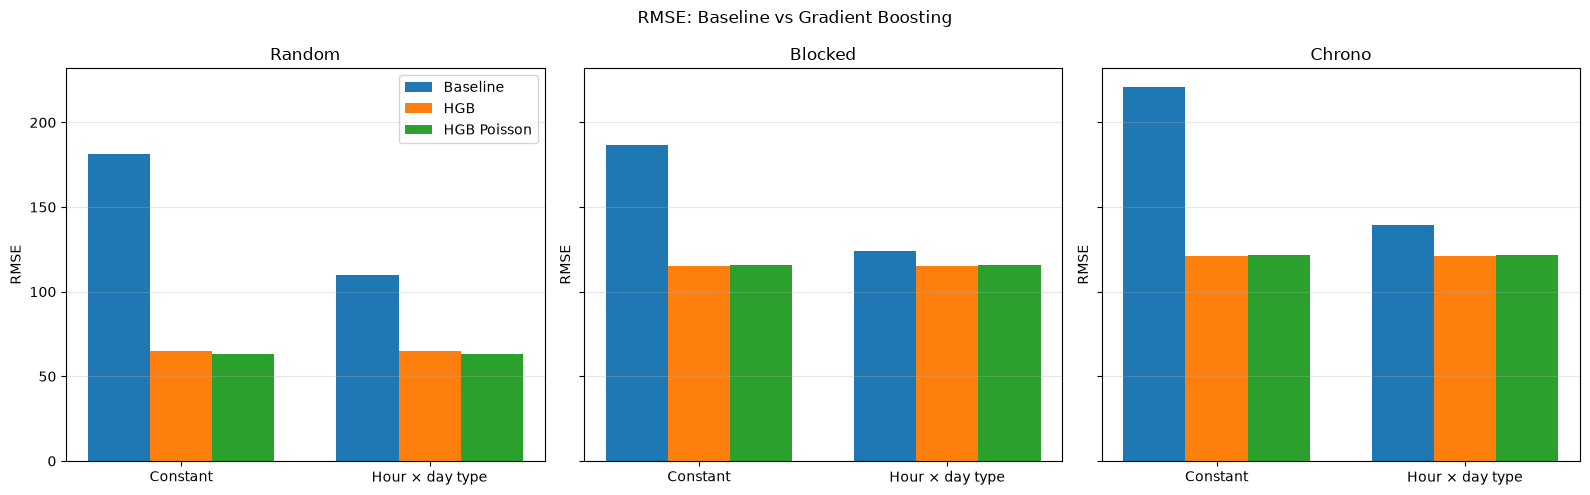

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for ax, scheme in zip(axes, SCHEMES):
    subset = baseline_comparison[baseline_comparison["scheme"] == scheme]
    x = np.arange(len(baseline_models))
    width = 0.25
    base_values, hgb_values, poisson_values = [], [], []

    for baseline_name in baseline_models:
        rows = subset[subset["baseline"] == baseline_name].set_index("model")
        base_values.append(rows["baseline_rmse"].iloc[0])
        hgb_values.append(rows.loc["hgb", "model_rmse"])
        poisson_values.append(rows.loc["hgb_poisson", "model_rmse"])

    ax.bar(x - width, base_values, width, label="Baseline")
    ax.bar(x, hgb_values, width, label="HGB")
    ax.bar(x + width, poisson_values, width, label="HGB Poisson")
    ax.set_title(scheme.capitalize())
    ax.set_xticks(x)
    ax.set_xticklabels(["Constant", "Hour × day type"])
    ax.set_ylabel("RMSE")
    ax.grid(axis="y", alpha=0.3)

axes[0].legend()
fig.suptitle("RMSE: Baseline vs Gradient Boosting")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "hgb_baseline_rmse_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## Selected Hyperparameters

For every outer fold, GridSearchCV selects the parameter combination with the lowest mean RMSE on the corresponding inner validation splits.

We inspect the selected parameters to understand how model complexity and regularisation vary across validation schemes and folds.

In [16]:
hgb_param_rows = []

for (model_name, scheme), (folds, preds) in hgb_results.items():
    for _, row in folds.iterrows():
        params = ast.literal_eval(row["best_params"]) if isinstance(row["best_params"], str) else row["best_params"]
        hgb_param_rows.append({"model": model_name, "scheme": scheme, "fold": row["fold"], **params})

hgb_params = pd.DataFrame(hgb_param_rows)
display(hgb_params.sort_values(["model", "scheme", "fold"]).reset_index(drop=True))

,model,scheme,fold,l2_regularization,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf
0,hgb,blocked,1,10.0,0.05,200,15,20
1,hgb,blocked,2,0.0,0.05,200,31,20
2,hgb,blocked,3,0.0,0.05,500,15,100
3,hgb,blocked,4,10.0,0.10,200,15,100
4,hgb,blocked,5,10.0,0.05,200,31,100
5,hgb,chrono,1,10.0,0.05,500,31,20
6,hgb,chrono,2,0.0,0.05,500,31,20
7,hgb,chrono,3,0.0,0.10,500,15,20
8,hgb,chrono,4,10.0,0.05,500,31,100
9,hgb,chrono,5,0.0,0.10,500,15,20


The selected parameters represent the best configurations within the tested grid.

If a parameter repeatedly reaches its minimum or maximum grid value, this may indicate that the search range should be expanded. Therefore, the selected values should not automatically be interpreted as globally optimal.

In [17]:
if isinstance(params, str):
    params = ast.literal_eval(params)

## Chronological Validation Folds

Chronological validation trains on earlier observations and evaluates on later observations.

The following table shows the date ranges of the training and test sets for each outer fold. The training set expands over time, while each test fold represents a later time period.

In [18]:
chrono_splits = list(get_cv("chrono", n_splits=5).split(X, y))
chrono_fold_tables = []

for model_name in ["hgb", "hgb_poisson"]:
    folds, _ = hgb_results[(model_name, "chrono")]
    fold_table = folds.copy()
    fold_table["train_start"] = [X.index[train_idx[0]] for train_idx, _ in chrono_splits]
    fold_table["train_end"] = [X.index[train_idx[-1]] for train_idx, _ in chrono_splits]
    fold_table["model"] = model_name
    chrono_fold_tables.append(fold_table[["model", "fold", "n_train", "n_test", "train_start", "train_end", "test_start", "test_end", "rmse", "mae"]])

chrono_folds_summary = pd.concat(chrono_fold_tables, ignore_index=True)
display(chrono_folds_summary.round({"rmse": 3, "mae": 3}))

,model,fold,n_train,n_test,train_start,train_end,test_start,test_end,rmse,mae
0,hgb,1,8657,1746,2011-01-01,2012-01-01 11:00:00,2012-01-01 12:00:00,2012-03-14 13:00:00,105.110,74.440
1,hgb,2,10403,1753,2011-01-01,2012-03-14 13:00:00,2012-03-14 14:00:00,2012-05-26 16:00:00,128.649,93.520
2,hgb,3,12156,1754,2011-01-01,2012-05-26 16:00:00,2012-05-26 17:00:00,2012-08-07 18:00:00,123.663,91.658
3,hgb,4,13910,1754,2011-01-01,2012-08-07 18:00:00,2012-08-07 19:00:00,2012-10-19 20:00:00,135.722,99.965
4,hgb,5,15664,1715,2011-01-01,2012-10-19 20:00:00,2012-10-19 21:00:00,2012-12-31 23:00:00,110.300,76.603
5,hgb_poisson,1,8657,1746,2011-01-01,2012-01-01 11:00:00,2012-01-01 12:00:00,2012-03-14 13:00:00,109.220,76.580
6,hgb_poisson,2,10403,1753,2011-01-01,2012-03-14 13:00:00,2012-03-14 14:00:00,2012-05-26 16:00:00,130.826,94.667
7,hgb_poisson,3,12156,1754,2011-01-01,2012-05-26 16:00:00,2012-05-26 17:00:00,2012-08-07 18:00:00,123.235,90.869
8,hgb_poisson,4,13910,1754,2011-01-01,2012-08-07 18:00:00,2012-08-07 19:00:00,2012-10-19 20:00:00,134.578,98.153
9,hgb_poisson,5,15664,1715,2011-01-01,2012-10-19 20:00:00,2012-10-19 21:00:00,2012-12-31 23:00:00,109.015,75.550


## Negative Predictions

A regression model with squared error loss can produce negative predictions, even though bike rental demand cannot be negative.

The Poisson model uses a logarithmic link and is designed for non-negative count targets. We therefore expect its predictions to be non-negative.

We measure the number and proportion of negative predictions in each validation scheme.

In [19]:
negative_rows = []

for (model_name, scheme), (folds, preds) in hgb_results.items():
    negative_count = (preds["y_pred"] < 0).sum()
    total_count = len(preds)
    negative_rows.append({"model": model_name, "scheme": scheme, "negative_predictions": negative_count, "total_predictions": total_count, "negative_percentage": negative_count / total_count * 100})

negative_summary = pd.DataFrame(negative_rows)
display(negative_summary.round(3))

assert (negative_summary.loc[negative_summary["model"] == "hgb_poisson", "negative_predictions"] == 0).all()

,model,scheme,negative_predictions,total_predictions,negative_percentage
0,hgb,random,307,17379,1.766
1,hgb,blocked,364,17379,2.094
2,hgb,chrono,138,8722,1.582
3,hgb_poisson,random,0,17379,0.000
4,hgb_poisson,blocked,0,17379,0.000
5,hgb_poisson,chrono,0,8722,0.000


## Actual vs Predicted

We compare actual and predicted demand for the chronological validation scheme. This helps identify systematic underestimation or overestimation and shows how well the models capture the range of observed demand.

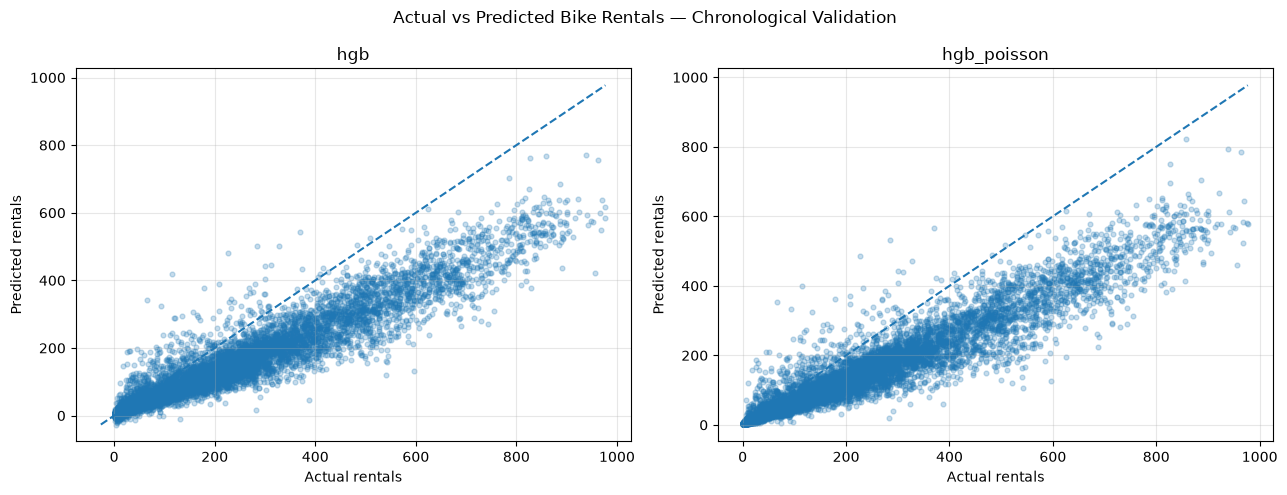

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, model_name in zip(axes, ["hgb", "hgb_poisson"]):
    _, preds = hgb_results[(model_name, "chrono")]

    ax.scatter(preds["y_true"], preds["y_pred"], alpha=0.25, s=12)

    lower = min(preds["y_true"].min(), preds["y_pred"].min())
    upper = max(preds["y_true"].max(), preds["y_pred"].max())

    ax.plot([lower, upper], [lower, upper], linestyle="--")

    ax.set_title(model_name)
    ax.set_xlabel("Actual rentals")
    ax.set_ylabel("Predicted rentals")
    ax.grid(alpha=0.3)

fig.suptitle("Actual vs Predicted Bike Rentals — Chronological Validation")
plt.tight_layout()

plt.savefig("figures/gradient_boosting/hgb_actual_vs_predicted_chrono.png",dpi=150, bbox_inches="tight")
plt.show()

### Residuals vs Predicted Values

Residuals are calculated as:

$$
e_i = y_i - \hat{y}_i
$$

Positive residuals indicate underestimation, while negative residuals indicate overestimation. A systematic pattern in the residual plot suggests that the model does not capture some structure in the data.

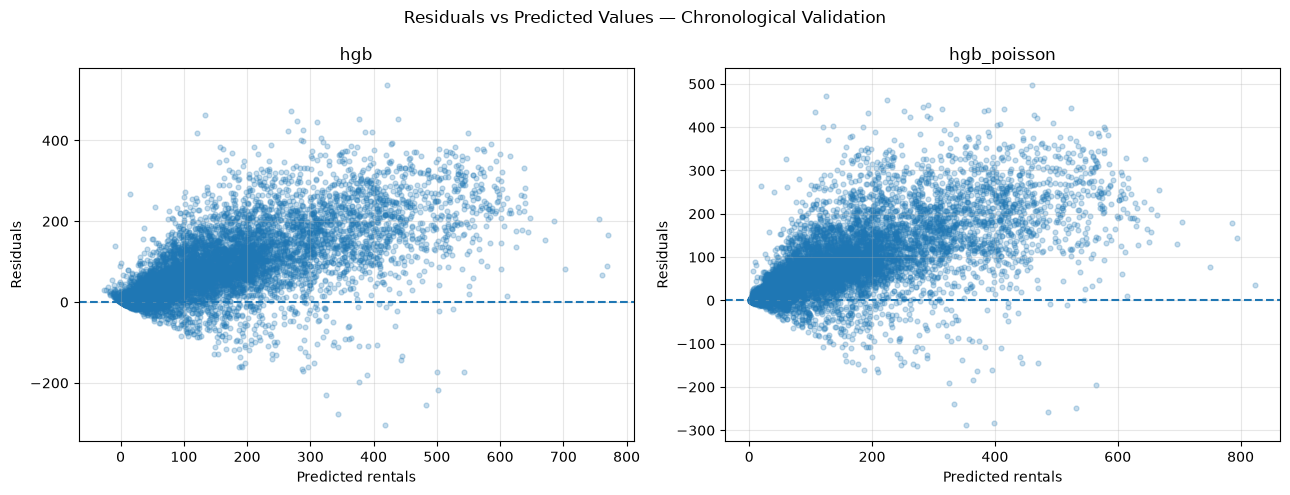

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, model_name in zip(axes, ["hgb", "hgb_poisson"]):
    _, preds = hgb_results[(model_name, "chrono")]

    residuals = preds["y_true"] - preds["y_pred"]

    ax.scatter(preds["y_pred"], residuals, alpha=0.25, s=12)
    ax.axhline(0, linestyle="--")
    ax.set_title(model_name)
    ax.set_xlabel("Predicted rentals")
    ax.set_ylabel("Residuals")
    ax.grid(alpha=0.3)

fig.suptitle("Residuals vs Predicted Values — Chronological Validation")
plt.tight_layout()

plt.savefig("figures/gradient_boosting/hgb_residuals_vs_predicted_chrono.png", dpi=150, bbox_inches="tight")
plt.show()

## Error Analysis

We analyse chronological predictions in more detail.

The analysis focuses on:

- prediction errors across hours of the day;
- the mean residual for each month;
- the contribution of systematic bias to the mean squared error;
- observations with the largest absolute prediction errors;
- the proportion of test observations whose target exceeds the maximum target value in the corresponding training set.

The final diagnostic measures how often test target values exceed the maximum target value observed in the corresponding training set.
This helps identify changes in the target range between training and test periods. It does not imply that HistGradientBoostingRegressor predictions are mathematically restricted to the training target range, nor does it prove that target values above this maximum are the sole cause of prediction errors.

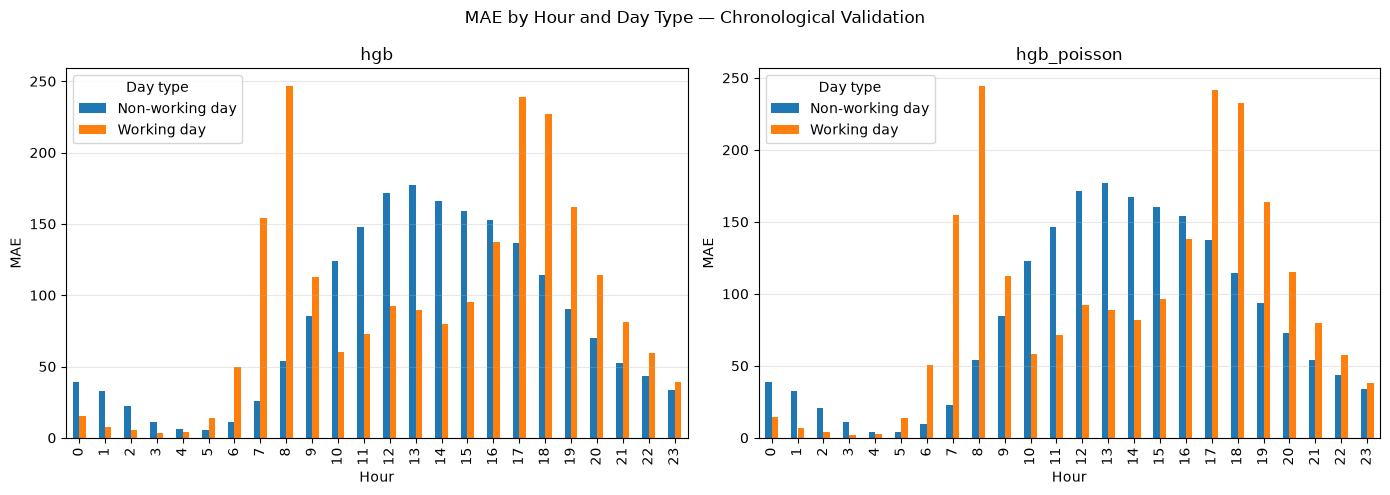

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model_name in zip(axes, ["hgb", "hgb_poisson"]):
    _, preds = hgb_results[(model_name, "chrono")]

    error_data = preds.join(X[["hr", "workingday"]], how="left")
    error_data["absolute_error"] = (error_data["y_true"] - error_data["y_pred"]).abs()

    hourly_mae = (error_data.groupby(["hr", "workingday"])["absolute_error"].mean().unstack())

    hourly_mae.plot(kind="bar", ax=ax)

    ax.set_title(model_name)
    ax.set_xlabel("Hour")
    ax.set_ylabel("MAE")
    ax.legend(["Non-working day", "Working day"], title="Day type")
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("MAE by Hour and Day Type — Chronological Validation")
plt.tight_layout()

plt.savefig("figures/gradient_boosting/hgb_mae_by_hour_chrono.png", dpi=150, bbox_inches="tight")
plt.show()